# 01 — EDA: estructura del dataset

Objetivo: entender qué hay en los datos **antes** de modelar. Este notebook no entrena nada.

- Cuántas filas y columnas hay, y cómo se reparten por escenario.
- Cuántas filas son ataque y cuántas benignas.
- Qué columnas tienen nulos y cómo se agrupan las 139 features.
- Por qué el precio MQTT es una fuga y se descarta.
- Qué transformación ve el modelo y cuánto de cada feature es "reloj".

El modelado va aparte, en `02_supervisado.ipynb`.

## Antes de empezar: si lo abrís en Google Colab

Este notebook vive en el repo y lee `datasets/`, `src/`, `resultados/` y `modelos/` desde la raíz del proyecto. En Colab esos archivos no existen, así que la celda de abajo clona el repo en `/content/data4cyber` y se para ahí.

**Cómo abrirlo:**

1. En Colab: *Archivo → Abrir notebook → GitHub*, pegá la URL del repo y elegí el notebook.
2. Ejecutá la primera celda. Clona el repo (una sola vez por sesión) y queda listo para correr.

Fuera de Colab la celda no hace nada.


In [1]:
# --- Preparar el entorno: solo hace algo si estás en Google Colab ---
import os
import subprocess
from pathlib import Path

REPO = "https://github.com/maxiricalde/data4cyber.git"
DESTINO = Path("/content/data4cyber")

try:
    import google.colab  # noqa: F401

    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    # Una sola vez por sesión: clonar el repo y pararse en su raíz.
    if not (DESTINO / "src" / "data.py").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO, str(DESTINO)], check=True)
    os.chdir(DESTINO)
    print("proyecto en:", os.getcwd())
else:
    print("corriendo local: no hay nada que preparar")


corriendo local: no hay nada que preparar


In [2]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

# El notebook vive en notebooks/, pero los datasets y src/ están en la raíz del proyecto.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "data.py").exists())
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))

from src.data import build_matrices  # solo se usa para quitar la capa de anotación

pd.set_option("display.width", 140)
print("raíz del proyecto:", RAIZ)

raíz del proyecto: /media/windows/Users/pablo/Documents/UNSA/4to/MetodosCuantitativos/TPFinal


## 1. Cargar los datos

Un CSV por escenario. Los ocho tienen las mismas columnas: sensores eléctricos, estado de batería,
un perfil del escenario (`Profile.*`) y la capa de anotación del ataque.

In [3]:
ESCENARIOS = ("S0", "S1", "S1alt", "S2", "S3", "S4", "S5", "S6")

datos = pd.concat(
    [pd.read_csv(f"datasets/dataset{nombre}.csv").assign(scenario=nombre) for nombre in ESCENARIOS],
    ignore_index=True,
)

print(f"filas totales: {len(datos):,}")
print("columnas por escenario:", datos.shape[1])

filas totales: 14,354
columnas por escenario: 157


### Cómo se ve una fila

No tiene sentido imprimir 157 columnas: miramos algunas de cada grupo (tiempo, etiqueta, perfil,
medidor), el tipo de dato y los nulos.

In [4]:
columnas_de_interes = [
    "timestamp",
    "attack_active",
    "Profile.pv_active_kw",
    "Substation-AC-Meter.p_sum3",
]

display(datos[columnas_de_interes].head())

print("tipos de columna:")
display(datos.dtypes.value_counts().to_frame("columnas"))

print("porcentaje de nulos, 10 columnas con más faltantes:")
display((100 * datos.isna().mean()).sort_values(ascending=False).head(10).round(2).to_frame("pct_nulos"))

,timestamp,attack_active,Profile.pv_active_kw,Substation-AC-Meter.p_sum3
0,2026-03-05 13:19:02.660000+00:00,False,NaN,-5902.140137
1,2026-03-05 13:19:03.660000+00:00,False,NaN,-5902.140137
2,2026-03-05 13:19:04.660000+00:00,False,NaN,-5902.140137
3,2026-03-05 13:19:05.660000+00:00,False,NaN,-5902.140137
4,2026-03-05 13:19:06.660000+00:00,False,NaN,-17.070137


tipos de columna:


,columnas
float64,150
str,6
bool,1


porcentaje de nulos, 10 columnas con más faltantes:


,pct_nulos
MQTT-Price-Signal.event,90.51
MQTT-Price-Signal.price_eur_per_kwh,6.77
Battery-SOC-Reported.soc_value,1.40
Profile.load2_kw,1.37
Profile.pv_reactive_kvar,1.37
Profile.pv_active_kw,1.37
Profile.pv_input_kw,1.37
Profile.load1_kw,1.37
Profile.ambient_temperature,1.37
Profile.timestamp,1.37


### Filas por escenario

Cada escenario tiene ~1.800 filas, una por segundo. No son ocho datasets distintos: son ocho
corridas continuas de la misma planta.

In [5]:
filas_por_escenario = datos.groupby("scenario").size().rename("filas").to_frame()
display(filas_por_escenario)

,filas
scenario,
S0,1798
S1,1798
S1alt,1792
S2,1768
S3,1800
S4,1798
S5,1800
S6,1800


## 2. De la tabla cruda a `X` e `y`

`build_matrices` descarta la capa de anotación y devuelve:

- `X`: las columnas de sensores (139 features).
- `y_binary`: 1 si la fila es ataque, 0 si es benigna.
- `scenario`: a qué escenario pertenece cada fila.
- `position`: posición relativa dentro del escenario, de 0 a 1. No es una feature: es el control
  de la sección 5 del notebook de modelado.

Veamos exactamente qué columnas se descartan y por qué.

In [6]:
m = build_matrices(datos)

descartadas = [c for c in datos.columns if c not in m.X.columns]
print(f"X: {m.X.shape[0]:,} filas x {m.X.shape[1]} features")
print(f"columnas descartadas: {len(descartadas)}")
display(pd.Series(descartadas, name="columna").to_frame())

X: 14,354 filas x 139 features
columnas descartadas: 18


,columna
0,timestamp
1,attack_active
2,attack_phase
3,attack_phase_all
4,BSS-Inverter-AC-Meter.phase_seq
5,BSS-Inverter-AC-Meter.realtime
6,Load-A-AC-Meter.phase_seq
7,Load-A-AC-Meter.realtime
8,Load-B-AC-Meter.phase_seq
9,Load-B-AC-Meter.realtime


Son tres grupos:

1. **Etiquetas** (`attack_active`, `attack_phase`, `attack_phase_all`): son la respuesta, no una
   medición.
2. **Tiempo** (`timestamp`, `Profile.timestamp`, relojes de dispositivo): el instante no es una
   medición de la planta.
3. **Fuga** (`MQTT-Price-Signal.event` y el precio): se justifica en la sección 3.

`scenario` también sale de `X`: es el identificador del fold, no una feature.

,ataque,benigno,filas
scenario,,,
S0,0,1798,1798
S1,913,885,1798
S1alt,910,882,1792
S2,903,865,1768
S3,912,888,1800
S4,1257,541,1798
S5,1341,459,1800
S6,1350,450,1800


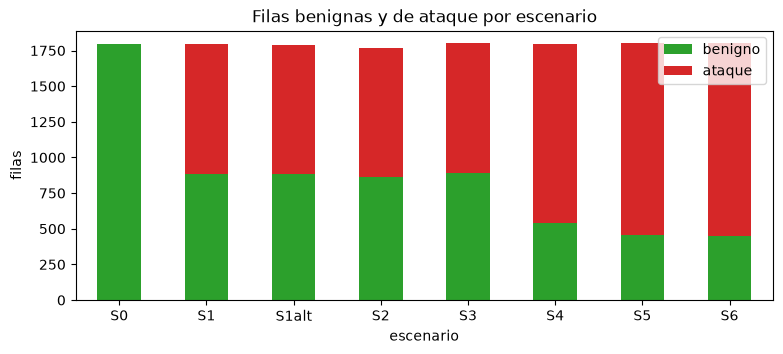

In [7]:
resumen = pd.DataFrame(
    {
        "ataque": m.y_binary.groupby(m.scenario).sum().astype(int),
        "benigno": (1 - m.y_binary).groupby(m.scenario).sum().astype(int),
    }
)
resumen["filas"] = resumen.sum(axis=1)
display(resumen)

resumen[["benigno", "ataque"]].plot.bar(
    stacked=True, color=["tab:green", "tab:red"], figsize=(9, 3.5)
)
plt.title("Filas benignas y de ataque por escenario")
plt.xlabel("escenario")
plt.ylabel("filas")
plt.xticks(rotation=0)
plt.legend(["benigno", "ataque"])
plt.show()

Ojo con el desbalance: en S4, S5 y S6 la mayoría de las filas son ataque. Por eso la exactitud
(accuracy) sola engaña, y por eso los modelos usan pesos balanceados.

### Nulos

Las 139 columnas tienen al menos un faltante, pero el peor caso es 1,40 % (201 filas): el dataset no
está lleno de huecos, tiene huecos chicos y repartidos. Igual hay que tratarlos: el pipeline imputa con
la mediana **ajustada solo con el entrenamiento de cada fold**.

In [8]:
nulos = m.X.isna().sum()
tabla_nulos = pd.DataFrame({"nulos": nulos, "pct": (100 * nulos / len(m.X)).round(2)})
tabla_nulos = tabla_nulos[tabla_nulos["nulos"] > 0].sort_values("nulos", ascending=False)

print(f"columnas con nulos: {len(tabla_nulos)} de {m.X.shape[1]}")
display(tabla_nulos.head(15))

columnas con nulos: 139 de 139


,nulos,pct
Battery-SOC-Reported.soc_value,201,1.40
Profile.load2_kw,196,1.37
Profile.load1_kw,196,1.37
Profile.ambient_temperature,196,1.37
Profile.pv_active_kw,196,1.37
Profile.total_irradiance,196,1.37
Profile.pv_reactive_kvar,196,1.37
Profile.pv_input_kw,196,1.37
Battery-SOC-Reference.soc_value,50,0.35
BSS-Inverter-AC-Meter.cos_phi2,31,0.22


### Cómo se agrupan las 139 features

El prefijo antes del punto es el equipo que mide. Cinco medidores AC aportan 26 señales cada uno
(tensiones, corrientes, potencias, factor de potencia y frecuencia); el resto es estado de batería y
perfil del escenario.

In [9]:
grupos = {}
for columna in m.X.columns:
    equipo, _, senal = columna.partition(".")
    grupos.setdefault(equipo, []).append(senal)

tabla_grupos = pd.DataFrame(
    [
        {"grupo": equipo, "features": len(senales), "columnas": ", ".join(senales)}
        for equipo, senales in grupos.items()
    ]
)
display(tabla_grupos)
print("total:", sum(len(senales) for senales in grupos.values()))

,grupo,features,columnas
0,BSS-Inverter-AC-Meter,26,"cos_phi1, cos_phi2, cos_phi3, freq, i_sum3, il..."
1,Battery-SOC-Reference,1,soc_value
2,Battery-SOC-Reported,1,soc_value
3,Load-A-AC-Meter,26,"cos_phi1, cos_phi2, cos_phi3, freq, i_sum3, il..."
4,Load-B-AC-Meter,26,"cos_phi1, cos_phi2, cos_phi3, freq, i_sum3, il..."
5,PV-Inverter-AC-Meter,26,"cos_phi1, cos_phi2, cos_phi3, freq, i_sum3, il..."
6,Profile,7,"ambient_temperature, load1_kw, load2_kw, pv_ac..."
7,Substation-AC-Meter,26,"cos_phi1, cos_phi2, cos_phi3, freq, i_sum3, il..."


total: 139


## 3. La fuga: el precio MQTT

Una feature es una **fuga** cuando es consecuencia del ataque y no una medición de la planta.
En S6 el ataque es de *supply chain* MQTT: el atacante publica un precio falso. Entonces el precio no
mide el sistema, mide **lo que el atacante escribió**.

`build_matrices(..., include_price=True)` deja la columna adentro solo para este control.

In [10]:
con_precio = build_matrices(datos, include_price=True)
precio = con_precio.X["MQTT-Price-Signal.price_eur_per_kwh"]

s6 = (m.scenario == "S6").to_numpy()
ataque_s6 = m.y_binary[s6].to_numpy()

tabla_precio = pd.crosstab(precio[s6].round(3), ataque_s6, dropna=False)
tabla_precio.index = [
    f"{valor:.3f}" if pd.notna(valor) else "sin dato" for valor in tabla_precio.index
]
tabla_precio.columns = ["benigno", "ataque"]
print("S6: filas por valor publicado de precio")
display(tabla_precio)

# Regla ingenua: "si hay precio publicado, es ataque".
publicado = precio[s6].notna().to_numpy()
tp = int(((publicado == 1) & (ataque_s6 == 1)).sum())
fp = int(((publicado == 1) & (ataque_s6 == 0)).sum())
fn = int(((publicado == 0) & (ataque_s6 == 1)).sum())
tn = int(((publicado == 0) & (ataque_s6 == 0)).sum())
display(pd.DataFrame({"TP": [tp], "FP": [fp], "FN": [fn], "TN": [tn]}, index=["regla: precio publicado"]))

precio_imputado = precio.fillna(precio[~s6].median())
print(
    "AUC del precio en S6, imputado con la mediana del resto:",
    round(roc_auc_score(ataque_s6, precio_imputado[s6]), 3),
)

S6: filas por valor publicado de precio


,benigno,ataque
2.118,0,450
2.230,0,450
2.307,12,450
sin dato,438,0


,TP,FP,FN,TN
regla: precio publicado,1350,12,0,438


AUC del precio en S6, imputado con la mediana del resto: 0.978


La tabla no deja dudas:

- las 1.350 filas de ataque publican precio 2,118, 2,230 o 2,307;
- 438 de las 450 filas benignas no tienen precio (canal vacío);
- las 12 benignas restantes publican 2,307: son la transición.

La regla "hay precio publicado" da **TP 1.350, FP 12, FN 0, TN 438**. Una sola columna da
**AUC 0,978** en S6.

Eso no es detectar el ataque: es leer el valor que el ataque escribió. Por eso queda fuera de `X`.

## 4. Qué ve el modelo: rango móvil de 120 s

El modelo no ve niveles crudos, ve cuánto se movió cada señal en los últimos dos minutos. Así el ciclo
día/noche deja de ser una pista.

La transformación es causal: cada fila usa solo su pasado dentro del escenario.

In [11]:
def rango_movil(X, escenario, ventana=120):
    """Máximo - mínimo en una ventana móvil, dentro de cada escenario.

    Una fila es un segundo. La ventana de 120 s mide volatilidad local y saca la
    tendencia lenta. Las primeras filas usan una ventana más corta (min_periods=1).
    """
    ventana_rodante = X.groupby(escenario).rolling(ventana, min_periods=1)
    maximo = ventana_rodante.max().reset_index(level=0, drop=True)
    minimo = ventana_rodante.min().reset_index(level=0, drop=True)
    return (maximo - minimo).reindex(X.index)


D = rango_movil(m.X, m.scenario)
print("features transformadas:", D.shape[1])

features transformadas: 139


Para verlo, buscamos en S3 el primer ataque sostenido (60 filas seguidas) y dibujamos el nivel crudo
contra el rango móvil en una ventana alrededor del inicio.

rango mediana antes del ataque: 14111.7
rango mediana durante el ataque: 3577.3


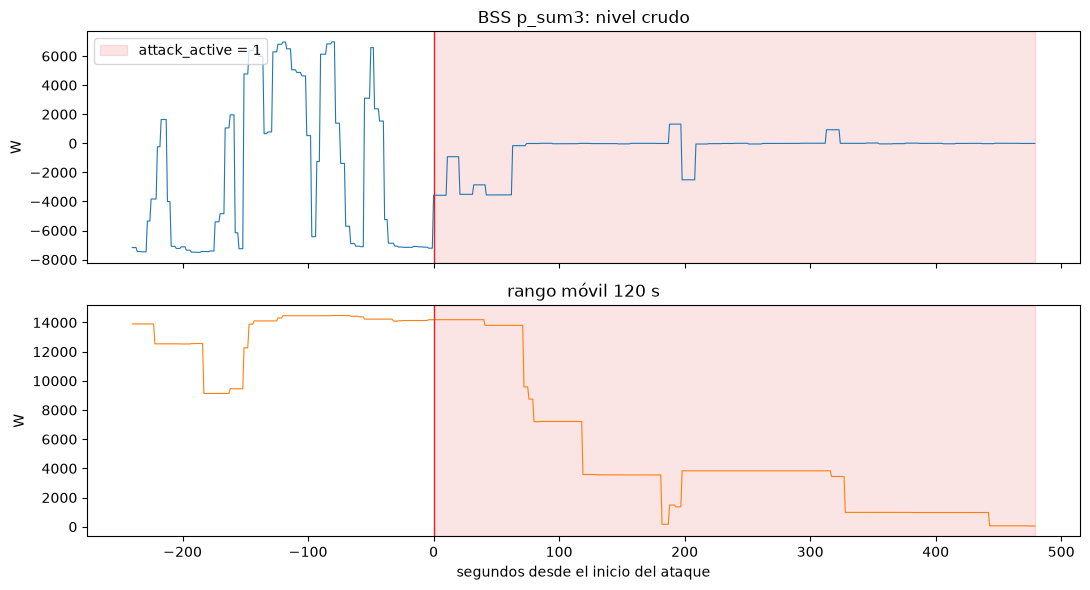

In [12]:
def primer_ataque_sostenido(etiquetas, minimo=60):
    """Posición del primer ataque que dura al menos `minimo` filas seguidas."""
    racha = 0
    for i, valor in enumerate(etiquetas):
        racha = racha + 1 if valor else 0
        if racha >= minimo:
            return i - minimo + 1
    return None


senal = "BSS-Inverter-AC-Meter.p_sum3"
y = m.y_binary.to_numpy()

filas_s3 = np.flatnonzero((m.scenario == "S3").to_numpy())
inicio_rel = primer_ataque_sostenido(y[filas_s3])
inicio = filas_s3[inicio_rel]

ventana = filas_s3[inicio_rel - 240 : inicio_rel + 480]
x = ventana - inicio
ataque = y[ventana] == 1

fig, ejes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ejes[0].plot(x, m.X[senal].to_numpy()[ventana], lw=0.8)
ejes[0].set_title("BSS p_sum3: nivel crudo")
ejes[1].plot(x, D[senal].to_numpy()[ventana], lw=0.8, color="tab:orange")
ejes[1].set_title("rango móvil 120 s")
ejes[1].set_xlabel("segundos desde el inicio del ataque")

for eje in ejes:
    eje.axvspan(0, x.max(), color="tab:red", alpha=0.12, label="attack_active = 1")
    eje.axvline(0, color="tab:red", lw=1)
    eje.set_ylabel("W")
ejes[0].legend(loc="upper left")

antes = ventana[ventana < inicio]
durante = ventana[(ventana >= inicio) & ataque]
print("rango mediana antes del ataque:", round(float(np.nanmedian(D[senal].to_numpy()[antes])), 1))
print("rango mediana durante el ataque:", round(float(np.nanmedian(D[senal].to_numpy()[durante])), 1))

fig.tight_layout()
plt.show()

En benigno el medidor **se mueve**: `p_sum3` salta miles de watts de una fila a otra. Durante el ARP
el medidor **se congela**: la señal queda en unos pocos valores cerca de 0. En esta ventana el rango
arranca en ~14.000 W y cae en escalones; en el conjunto de filas ARP la mediana es ~200 W frente a
~11.400 W en benigno.

El rango no premia "más movimiento": mide cuánto se movió. Acá el ataque **apaga el movimiento**. La
caída en escalones es la memoria de 2 minutos: a medida que la señal congelada reemplaza a la que se
movía, el rango baja.

El nivel crudo solo no alcanza: en benigno también hay ratos cerca de 0. Lo que cambia es la
dinámica, y eso es lo que deja la transformación.

### Por qué hacemos esto (y qué dice el paper)

El paper que usa este dataset (Kamran y Saman, 2026, sección III.A) ataca el mismo problema desde otro
lado: para que el modelo no haga trampa, evalúa con escenarios separados (LOSO), ordena las
particiones en el tiempo y deja un margen ("purge") entre entrenamiento y validación. Lo llama
"scenario shift" y "evaluación consciente de fugas".

Eso controla que el modelo no vea el futuro ni el escenario que tiene que predecir. Pero no dice nada
sobre lo que ve **dentro** de cada fila: si le pasamos el nivel crudo, el modelo puede aprender que
"de noche es benigno" sin aprender nada del ataque.

Por eso acá damos un paso más, y es una decisión nuestra, no del paper: en lugar del nivel le pasamos
el rango móvil de 120 s. La justificación es la medición de arriba. Y en la sección 5 vamos a ver que,
aun así, el reloj no desaparece del todo: la posición sigue correlacionando 0,226 con las features.

En una frase: **el paper cuida que el modelo no vea el futuro; nosotros además cuidamos que no aprenda
del calendario.**

## 5. Correlación: reloj contra señal

Dos preguntas distintas, con la misma herramienta (Spearman, que no supone relación lineal):

- **reloj**: cuánto correlaciona cada feature con la posición dentro del escenario;
- **ataque**: cuánto correlaciona cada feature con la etiqueta.

In [13]:
def abs_rho(columna, objetivo):
    """|rho de Spearman| entre una columna y un objetivo, imputando nulos con la mediana."""
    valores = D[columna]
    valores = valores.fillna(valores.median())
    return abs(spearmanr(valores, objetivo).statistic)


rho_reloj = pd.Series({c: abs_rho(c, m.position) for c in D.columns}).sort_values(ascending=False)
print("|rho| medio con la posición:", round(float(rho_reloj.mean()), 3))
display(rho_reloj.head(15).round(3).to_frame("abs_rho_posicion"))

|rho| medio con la posición: 0.226


,abs_rho_posicion
PV-Inverter-AC-Meter.i_sum3,0.503
BSS-Inverter-AC-Meter.sln2,0.495
BSS-Inverter-AC-Meter.s_sum3,0.493
BSS-Inverter-AC-Meter.sln3,0.491
BSS-Inverter-AC-Meter.sln1,0.489
Substation-AC-Meter.qln1,0.484
Substation-AC-Meter.qln3,0.479
Substation-AC-Meter.q_sum3,0.479
Substation-AC-Meter.qln2,0.478
BSS-Inverter-AC-Meter.iln1,0.474


In [14]:
rho_ataque = pd.Series({c: abs_rho(c, m.y_binary) for c in D.columns}).sort_values(ascending=False)
display(rho_ataque.head(15).round(3).to_frame("abs_rho_ataque"))

,abs_rho_ataque
Profile.load2_kw,0.483
PV-Inverter-AC-Meter.p_sum3,0.430
Substation-AC-Meter.qln3,0.411
BSS-Inverter-AC-Meter.i_sum3,0.411
Substation-AC-Meter.qln2,0.410
Substation-AC-Meter.q_sum3,0.410
BSS-Inverter-AC-Meter.sln1,0.409
BSS-Inverter-AC-Meter.pln1,0.408
BSS-Inverter-AC-Meter.p_sum3,0.404
BSS-Inverter-AC-Meter.iln2,0.404


Las features que están arriba en **las dos** columnas son el confound puro: correlacionan con el
ataque tanto como con el simple paso del tiempo.

In [15]:
ambas = pd.DataFrame({"reloj": rho_reloj, "ataque": rho_ataque})
ambas["minimo"] = ambas.min(axis=1)
print("features que están arriba en las dos:")
display(ambas.sort_values("minimo", ascending=False).head(10).round(3))

features que están arriba en las dos:


,reloj,ataque,minimo
PV-Inverter-AC-Meter.p_sum3,0.446,0.430,0.430
Substation-AC-Meter.qln3,0.479,0.411,0.411
BSS-Inverter-AC-Meter.i_sum3,0.465,0.411,0.411
Substation-AC-Meter.qln2,0.478,0.410,0.410
Substation-AC-Meter.q_sum3,0.479,0.410,0.410
BSS-Inverter-AC-Meter.sln1,0.489,0.409,0.409
BSS-Inverter-AC-Meter.pln1,0.426,0.408,0.408
BSS-Inverter-AC-Meter.p_sum3,0.427,0.404,0.404
BSS-Inverter-AC-Meter.iln2,0.471,0.404,0.404
BSS-Inverter-AC-Meter.pln2,0.430,0.402,0.402


### Redundancia entre features

Si dos columnas tienen |r| ≈ 1, una de las dos no aporta información nueva. Eso es lo que justifica
el filtro de correlación de la receta de 15 columnas.

In [16]:
umbral = 0.95
correlacion = D.corr(method="spearman").abs()
triangulo = (
    correlacion.where(np.triu(np.ones(correlacion.shape), k=1).astype(bool))
    .stack()
    .dropna()
    .sort_values(ascending=False)
)
print(f"pares de features con |r| > {umbral}: {int((triangulo > umbral).sum())} de {len(triangulo):,}")
display(triangulo.head(10).round(3).to_frame("abs_r"))

pares de features con |r| > 0.95: 265 de 9,591


abs_r
Load-B-AC-Meter.p_sum3 Load-B-AC-Meter.pln2    1.0
                       Load-B-AC-Meter.pln3    1.0
Load-B-AC-Meter.iln1   Load-B-AC-Meter.iln2    1.0
Load-B-AC-Meter.p_sum3 Load-B-AC-Meter.pln1    1.0
Load-B-AC-Meter.s_sum3 Load-B-AC-Meter.sln3    1.0
Load-B-AC-Meter.iln1   Load-B-AC-Meter.iln3    1.0
Profile.pv_active_kw   Profile.pv_input_kw     1.0
Load-B-AC-Meter.iln2   Load-B-AC-Meter.iln3    1.0
Load-B-AC-Meter.pln1   Load-B-AC-Meter.pln2    1.0
Load-B-AC-Meter.pln2   Load-B-AC-Meter.pln3    1.0

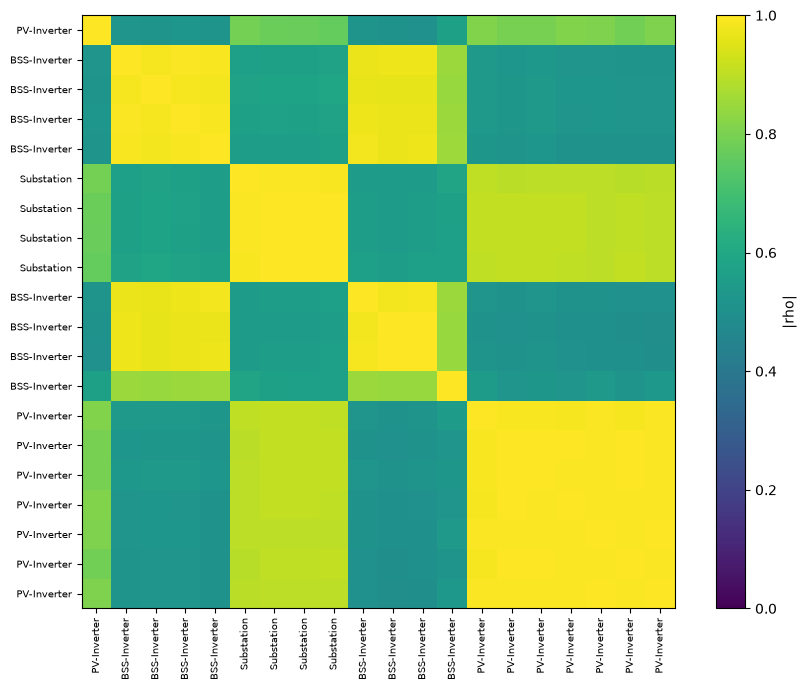

In [17]:
top = rho_reloj.head(20).index
etiquetas_cortas = [c.split(".")[0].replace("-AC-Meter", "") for c in top]

fig, eje = plt.subplots(figsize=(9, 7))
imagen = eje.imshow(correlacion.loc[top, top], cmap="viridis", vmin=0, vmax=1)
eje.set_xticks(range(len(top)), etiquetas_cortas, rotation=90, fontsize=7)
eje.set_yticks(range(len(top)), etiquetas_cortas, fontsize=7)
fig.colorbar(imagen, ax=eje, label="|rho|")
fig.tight_layout()
plt.show()

## Lo que queda fijado

- El precio MQTT es una fuga: una sola columna da 0,978 de AUC en S6. Queda fuera de `X`.
- El rango móvil de 120 s borra el nivel y deja la dinámica; es lo que ve el modelo.
- La correlación con la posición mide cuánto de cada feature es reloj; la correlación con la etiqueta
  mide cuánto es señal. Las que están arriba en las dos son el confound.
- La correlación entre features mide redundancia: 265 pares superan |r| = 0,95, y eso justifica el
  filtro de la receta reducida.

Siguiente paso: modelado supervisado en `02_supervisado.ipynb`.